# Industry classification

Use supplied business-description embeddings to compare logistic regression and
k-NN. Financial ranks support calibrated correctness confidence.
Place `df_train.pkl` and `df_financials_train.pkl` in `data/` beside this notebook.
Install the pinned packages in `requirements.txt` before running all cells.

The official score is **weighted F1 × (1 − correctness Brier)**. The final bonus
threshold will be determined on private test data; the indicative plain-LR
private score is about 0.66.
All comparisons below use the same local validation companies.

## Imports

In [1]:
import ast  # [01.01] Parse the supplied embedding strings as literal Python values.
from time import perf_counter  # [01.02] Measure elapsed time with a monotonic clock.
import numpy as np  # [01.03] Use arrays and vectorized numerical operations.
import pandas as pd  # [01.04] Load, join, group, and summarize tables.
import matplotlib.pyplot as plt  # [01.05] Create and label figures.
import seaborn as sns  # [01.06] Draw readable statistical plots.
from IPython.display import display  # [01.07] Display tables inside Jupyter.
from sklearn.decomposition import PCA  # [01.08] Import the principal-component transformation.
# [01.09] Import the classifier used for industries and correctness confidence.
from sklearn.linear_model import LogisticRegression
# [01.10] Import the required classification metrics.
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit  # [01.11] Split whole company-ID groups reproducibly.
from sklearn.neighbors import KNeighborsClassifier  # [01.12] Import the distance-weighted neighbor classifier.
# [01.13] Chain confidence scaling and logistic regression into one fitted object.
from sklearn.pipeline import make_pipeline
# [01.14] Encode industry names and scale the six confidence features.
from sklearn.preprocessing import LabelEncoder, StandardScaler
from threadpoolctl import threadpool_limits  # [01.15] Control numerical-library thread use.
threadpool_limits(2)  # [01.16] Limit numerical-library work to two threads.
started = perf_counter()  # [01.17] Start the notebook's elapsed-time measurement.


## Data and separation

Repeated financial IDs become one median financial record. Infinite values
become missing; negative values remain. Empirical ranks later bound the effect
of finite outliers. Company IDs remain together across approximately 81%
fitting, 9% confidence calibration, and 10% validation.

In [2]:
ratios = ['net_profit_margin', 'ebitda_margin', 'asset_turnover']  # [02.01] Name the three available financial ratios.
financial = pd.read_pickle('data/df_financials_train.pkl')  # [02.02] Load the supplied financial records.
# [02.03] Count missing and infinite values separately before cleaning.
display(pd.DataFrame({'Missing': financial[ratios].isna().sum(),
                      'Infinite': np.isinf(financial[ratios]).sum()}))
# [02.04] Treat infinities as missing and aggregate repeated financial IDs by median.
financial = financial.replace([np.inf, -np.inf], np.nan).groupby('id')[ratios].median()
# [02.05] Keep every company while joining at most one financial record per ID.
df = pd.read_pickle('data/df_train.pkl').merge(financial, on='id', how='left', validate='many_to_one')

def split(rows, size):  # [02.06] Reuse a short helper for company-group splits.
    # [02.07] Select one seeded split without separating repeated company IDs.
    left, right = next(GroupShuffleSplit(n_splits=1, test_size=size, random_state=42)
                       .split(rows, groups=rows.id))
    return rows.iloc[left], rows.iloc[right]  # [02.08] Select rows by their integer positions.

development, df_val = split(df, 0.1)  # [02.09] Reserve about ten percent of company IDs for validation.
df_fit, df_cal = split(development, 0.1)  # [02.10] Hold out part of development data for correctness calibration.
parts = [df_fit, df_cal, df_val]  # [02.11] Keep one consistent fitting/calibration/validation order.

def embeddings(rows):  # [02.12] Reuse the same embedding conversion at training and inference.
    # [02.13] Parse coordinate lists and store the numerical matrix as float32.
    return np.array(rows.business_description_embedding.apply(ast.literal_eval).tolist(), dtype=np.float32)

# [02.14] Convert each subset once and unpack the three matrices.
X_fit, X_cal, X_val = [embeddings(part) for part in parts]
le = LabelEncoder().fit(df_fit.industry)  # [02.15] Learn industry-to-code mapping from fitting labels.
# [02.16] Apply that same mapping to each target vector.
y_fit, y_cal, y_val = [le.transform(part.industry) for part in parts]
# [02.17] Print the actual record counts instead of assuming exact percentages.
print('Records:', len(df), '| fitting/calibration/validation:', [len(part) for part in parts])
counts = df_fit.industry.value_counts()  # [02.18] Count the records that actually teach the classifiers.
display(counts.rename('Fitting records').to_frame())  # [02.19] Display the required fitting-industry frequency table.


,Missing,Infinite
net_profit_margin,1111,2131
ebitda_margin,19279,824
asset_turnover,1363,5


Records: 31706 | fitting/calibration/validation: [25681, 2854, 3171]


,Fitting records
industry,
Materials,6797
Capital Goods,2516
"Pharmaceuticals, Biotechnology & Life Sciences",1563
Financial Services,1557
Technology Hardware & Equipment,1237
Software & Services,1220
Energy,1071
Consumer Durables & Apparel,921
"Food, Beverage & Tobacco",904


Materials has **6,797 fitting records (26.5%)**, compared with **151** for Consumer Staples Distribution & Retail. These are classifier-fitting counts. Financial records are not additional labeled companies.

## PCA and the two classifiers

PCA learns only from fitting embeddings. Its first two components visualize
industry overlap; all 128 retained components feed k-NN. Logistic regression
uses the original embeddings. A two-dimensional plot cannot show all class
separation in the original space.

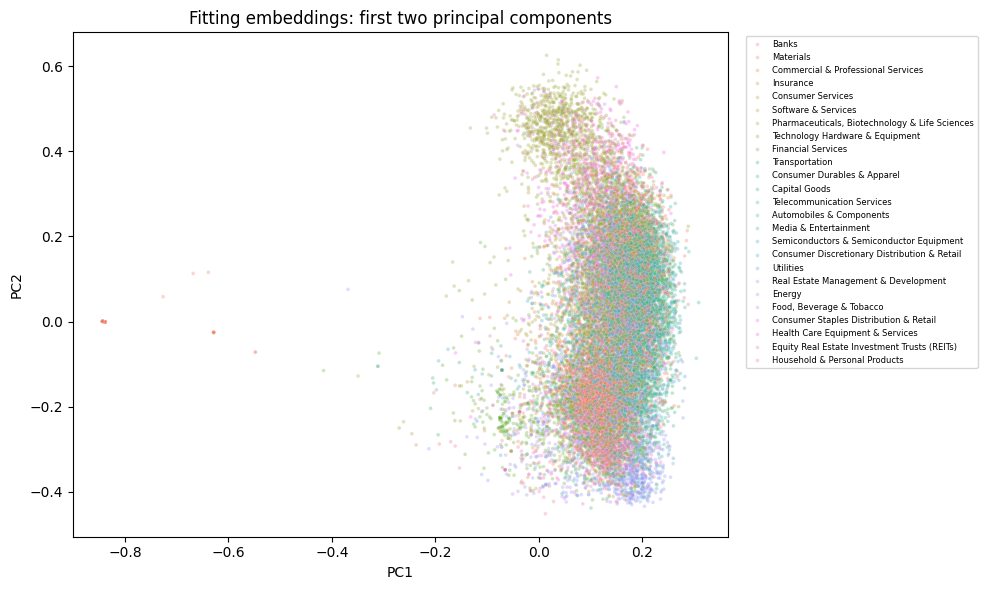

Variance retained, 2 and 128 components: 0.25287107 0.8762428


In [3]:
pca = PCA(n_components=128, random_state=42).fit(X_fit)  # [03.01] Learn 128 PCA axes using fitting embeddings only.
# [03.02] Project fitting embeddings with the same transformation later used for new inputs.
X_fit_pca = pca.transform(X_fit)
# [03.03] Prepare the first two coordinates and their industry labels for plotting.
plot = pd.DataFrame(X_fit_pca[:, :2], columns=['PC1', 'PC2']).assign(Industry=df_fit.industry.to_numpy())
plt.figure(figsize=(10, 6))  # [03.04] Choose a figure size that leaves room for the industry legend.
# [03.05] Color companies by industry to inspect overlap in two dimensions.
sns.scatterplot(data=plot, x='PC1', y='PC2', hue='Industry', s=7, alpha=0.3, palette='husl')
# [03.06] Place the many industry names beside the scatterplot.
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=6)
# [03.07] Identify the projected fitting data in the title.
plt.title('Fitting embeddings: first two principal components')
plt.tight_layout()  # [03.08] Adjust spacing so labels remain visible.
plt.show()  # [03.09] Show the PCA scatterplot.
# [03.10] Report how much fitting variance the displayed and retained components explain.
print('Variance retained, 2 and 128 components:', pca.explained_variance_ratio_[:2].sum(),
      pca.explained_variance_ratio_.sum())
# [03.11] Fit logistic regression on the original embedding coordinates.
lr = LogisticRegression(C=10, max_iter=1000).fit(X_fit, y_fit)
# [03.12] Store the fitting PCA vectors and labels for distance-weighted 15-neighbor prediction.
knn = KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=2).fit(X_fit_pca, y_fit)

def model_inputs(X):  # [03.13] Reuse the base-model probabilities and nearest-distance calculation.
    reduced = pca.transform(X)  # [03.14] Transform new vectors with the already fitted PCA.
    # [03.15] Return aligned LR probabilities, k-NN probabilities, and nearest distances.
    return (lr.predict_proba(X), knn.predict_proba(reduced),
            knn.kneighbors(reduced, n_neighbors=1)[0][:, 0])

# [03.16] Compute calibration and validation model inputs once.
input_cal, input_val = [model_inputs(X) for X in [X_cal, X_val]]


The first two components retain **25.3%** of fitting variance; 128 retain **87.6%**. Some regions separate visibly, while many industries overlap centrally. This projection alone does not establish classification performance in the original space.

## Required classifier comparison

Accuracy counts correct labels. Weighted F1 weights industries by validation
support; macro F1 weights industries equally. Row-normalized confusion plots
show which labels each true industry receives. Error pairs use raw counts.

,precision,recall,f1-score,support
Automobiles & Components,0.693548,0.716667,0.704918,60.0
Banks,0.971698,0.971698,0.971698,106.0
Capital Goods,0.639241,0.655844,0.647436,308.0
Commercial & Professional Services,0.490196,0.304878,0.375940,82.0
Consumer Discretionary Distribution & Retail,0.612245,0.526316,0.566038,57.0
Consumer Durables & Apparel,0.751938,0.757812,0.754864,128.0
Consumer Services,0.820000,0.706897,0.759259,58.0
Consumer Staples Distribution & Retail,0.428571,0.500000,0.461538,18.0
Energy,0.750000,0.647482,0.694981,139.0
Equity Real Estate Investment Trusts (REITs),0.906977,0.764706,0.829787,51.0


Logistic regression | fitting size / error-rate correlation: -0.36152789956384973


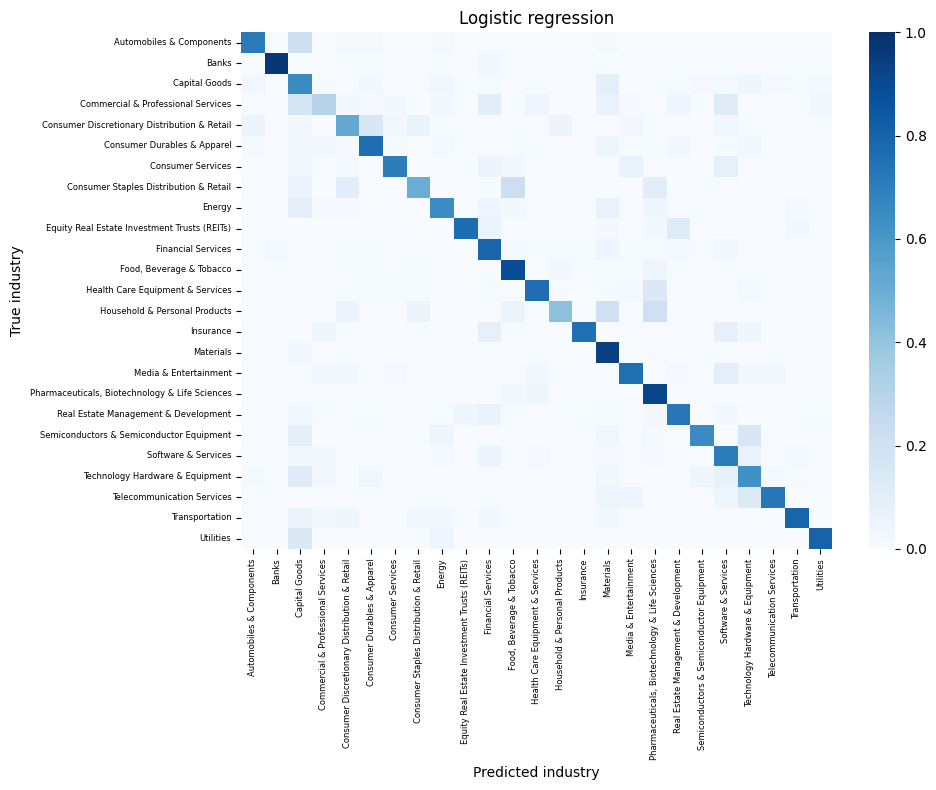

Capital Goods                       Materials                                         28
Technology Hardware & Equipment     Capital Goods                                     21
Materials                           Capital Goods                                     18
Commercial & Professional Services  Capital Goods                                     15
Health Care Equipment & Services    Pharmaceuticals, Biotechnology & Life Sciences    15
Name: Errors, dtype: int64

,precision,recall,f1-score,support
Automobiles & Components,0.681159,0.783333,0.728682,60.0
Banks,0.887931,0.971698,0.927928,106.0
Capital Goods,0.619938,0.646104,0.632750,308.0
Commercial & Professional Services,0.612903,0.231707,0.336283,82.0
Consumer Discretionary Distribution & Retail,0.574074,0.543860,0.558559,57.0
Consumer Durables & Apparel,0.743802,0.703125,0.722892,128.0
Consumer Services,0.803571,0.775862,0.789474,58.0
Consumer Staples Distribution & Retail,0.600000,0.333333,0.428571,18.0
Energy,0.809524,0.611511,0.696721,139.0
Equity Real Estate Investment Trusts (REITs),0.809524,0.666667,0.731183,51.0


k-NN | fitting size / error-rate correlation: -0.28268562449161944


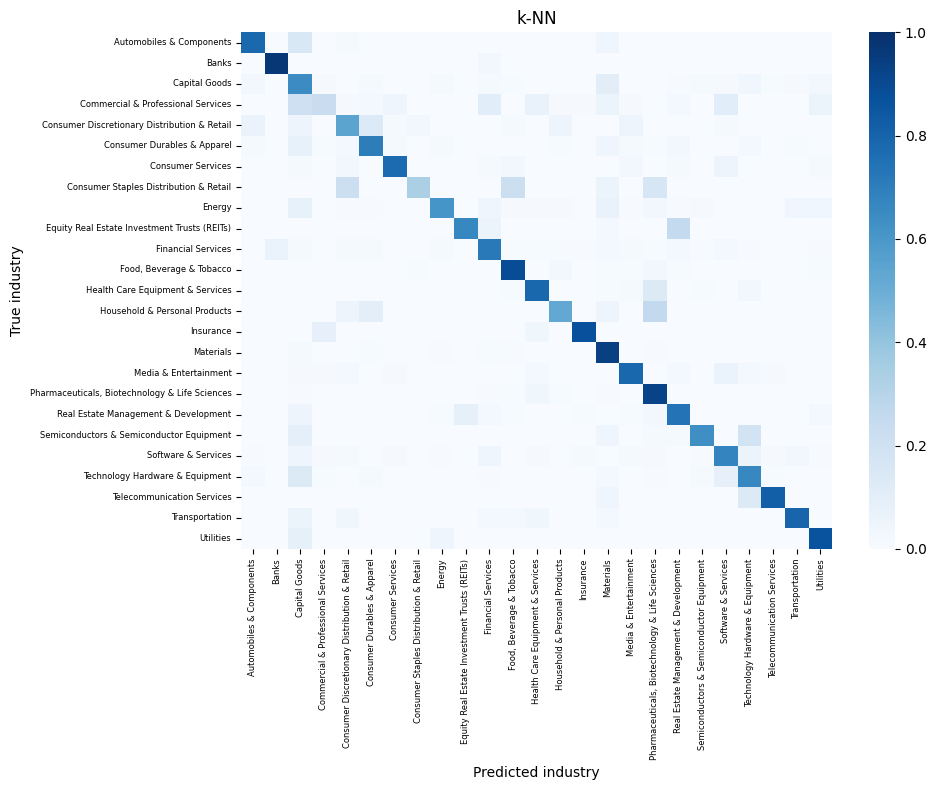

Capital Goods                       Materials              33
Technology Hardware & Equipment     Capital Goods          24
Commercial & Professional Services  Capital Goods          17
Materials                           Capital Goods          16
Technology Hardware & Equipment     Software & Services    15
Name: Errors, dtype: int64

,Model,Accuracy,Weighted F1,Macro F1
0,Logistic regression,0.781457,0.777788,0.717515
1,k-NN,0.777042,0.771401,0.710471


k-NN wrong,False,True
LR wrong,,
False,2291,187
True,173,520


In [4]:
comparison = []  # [04.01] Collect comparable aggregate classifier metrics.
# [04.02] Use one analysis loop for the two required classifiers.
for name, probabilities in zip(['Logistic regression', 'k-NN'], input_val[:2]):
    prediction = probabilities.argmax(1)  # [04.03] Choose the largest class probability in each row.
    # [04.04] Record accuracy, support-weighted F1, and equally weighted macro F1.
    comparison.append([name, accuracy_score(y_val, prediction),
                       f1_score(y_val, prediction, average='weighted'),
                       f1_score(y_val, prediction, average='macro')])
    # [04.05] Build per-industry precision, recall, F1, and support results.
    report = pd.DataFrame(classification_report(y_val, prediction, target_names=le.classes_,
                                                output_dict=True, zero_division=0)).T.loc[le.classes_]
    display(report)  # [04.06] Display the per-industry report.
    # [04.07] Compare fitting class size with validation error rate descriptively.
    print(name, '| fitting size / error-rate correlation:', counts.corr(1 - report.recall))
    # [04.08] Count every true-versus-predicted industry combination.
    matrix = pd.DataFrame(confusion_matrix(y_val, prediction), index=le.classes_, columns=le.classes_)
    plt.figure(figsize=(10, 8))  # [04.09] Choose a readable confusion-matrix figure size.
    # [04.10] Divide each row by its support before plotting.
    sns.heatmap(matrix.div(matrix.sum(1), axis=0), cmap='Blues', vmin=0, vmax=1)
    plt.xlabel('Predicted industry')  # [04.11] Label the predicted-industry axis.
    plt.ylabel('True industry')  # [04.12] Label the true-industry axis.
    plt.title(name)  # [04.13] Identify which classifier produced the confusion matrix.
    plt.xticks(fontsize=6)  # [04.14] Use smaller horizontal tick labels for the 25 industry names.
    plt.yticks(fontsize=6)  # [04.15] Use smaller vertical tick labels for the same class order.
    plt.tight_layout()  # [04.16] Keep the matrix labels inside the figure layout.
    plt.show()  # [04.17] Show the row-normalized confusion plot.
    np.fill_diagonal(matrix.values, 0)  # [04.18] Exclude correct predictions from the subsequent error-pair ranking.
    # [04.19] Display the five most frequent directed industry confusions.
    display(matrix.stack().nlargest(5).rename('Errors'))
# [04.20] Display both classifiers' aggregate metrics together.
display(pd.DataFrame(comparison, columns=['Model', 'Accuracy', 'Weighted F1', 'Macro F1']))
# [04.21] Count shared and model-specific mistakes on the same companies.
display(pd.crosstab(input_val[0].argmax(1) != y_val, input_val[1].argmax(1) != y_val,
                    rownames=['LR wrong'], colnames=['k-NN wrong']))


LR is stronger alone: weighted F1 **0.77779**, versus **0.77140** for k-NN. Macro F1 is lower (**0.71752** and **0.71047**), exposing weaker small-industry performance. Both models are wrong on **520** records; **173** errors are unique to LR and **187** to k-NN. Common confusions include Capital Goods versus Materials and Technology Hardware & Equipment versus Capital Goods.

## Financial evidence

Each fitting company contributes once to each industry reference. Boxplots
hide outlier dots for readability, while retaining those values in the
reference samples. Symmetric logarithmic axes also display losses.

net_profit_margin            \
                                                           count    median   
industry                                                                     
Automobiles & Components                                     475  0.034077   
Banks                                                        710  0.245811   
Capital Goods                                               2276  0.039592   
Commercial & Professional Services                           532  0.033262   
Consumer Discretionary Distribution & Retail                 473  0.017686   
Consumer Durables & Apparel                                  832  0.031132   
Consumer Services                                            469  0.028669   
Consumer Staples Distribution & Retail                       140  0.022693   
Energy                                                       795  0.043417   
Equity Real Estate Investment Trusts (REITs)                 323  0.252600   
Financial Services                                          1115  0.259259   
Food, Beverage & Tobacco                                     782  0.038511   
Health Care Equipment & Services                             678 -0.003701   
Household & Personal Products                                161  0.035555   
Insurance                                                    211  0.079118   
Materials                                                   5438  0.049562   
Media & Entertainment                                        620 -0.021711   
Pharmaceuticals, Biotechnology & Life Sciences              1074 -0.188698   
Real Estate Management & Development                         636  0.080751   
Semiconductors & Semiconductor Equipment                     457  0.042345   
Software & Services                                         1012  0.002503   
Technology Hardware & Equipment                             1143  0.025251   
Telecommunication Services                                   154  0.033975   
Transportation                                               434  0.070571   
Utilities                                                    414  0.085487   

                                               ebitda_margin            \
                                                       count    median   
industry                                                                 
Automobiles & Components                                 133  0.092523   
Banks                                                    209  0.256049   
Capital Goods                                            727  0.106101   
Commercial & Professional Services                       290  0.097789   
Consumer Discretionary Distribution & Retail             277  0.071807   
Consumer Durables & Apparel                              272  0.090690   
Consumer Services                                        260  0.147591   
Consumer Staples Distribution & Retail                    66  0.050672   
Energy                                                   338  0.165206   
Equity Real Estate Investment Trusts (REITs)             221  0.580373   
Financial Services                                       639  0.355395   
Food, Beverage & Tobacco                                 310  0.091367   
Health Care Equipment & Services                         411  0.004134   
Household & Personal Products                             78  0.105431   
Insurance                                                121  0.129391   
Materials                                                732  0.076083   
Media & Entertainment                                    324  0.040945   
Pharmaceuticals, Biotechnology & Life Sciences           572 -0.958235   
Real Estate Management & Development                     253  0.221348   
Semiconductors & Semiconductor Equipment                 102  0.035120   
Software & Services                                      543  0.016398   
Technology Hardware & Equipment                          308  0.044118   
Telecommunic

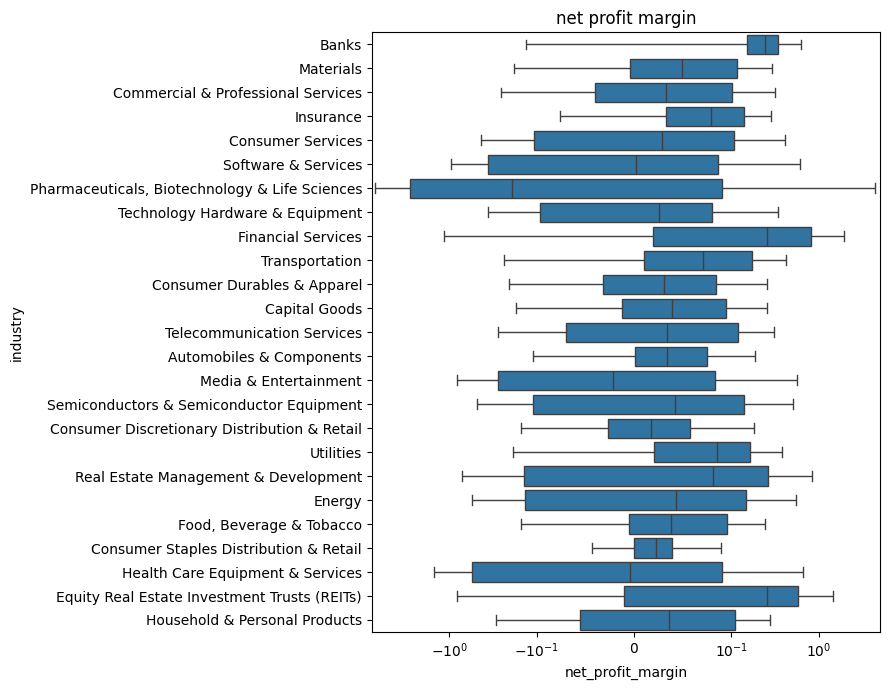

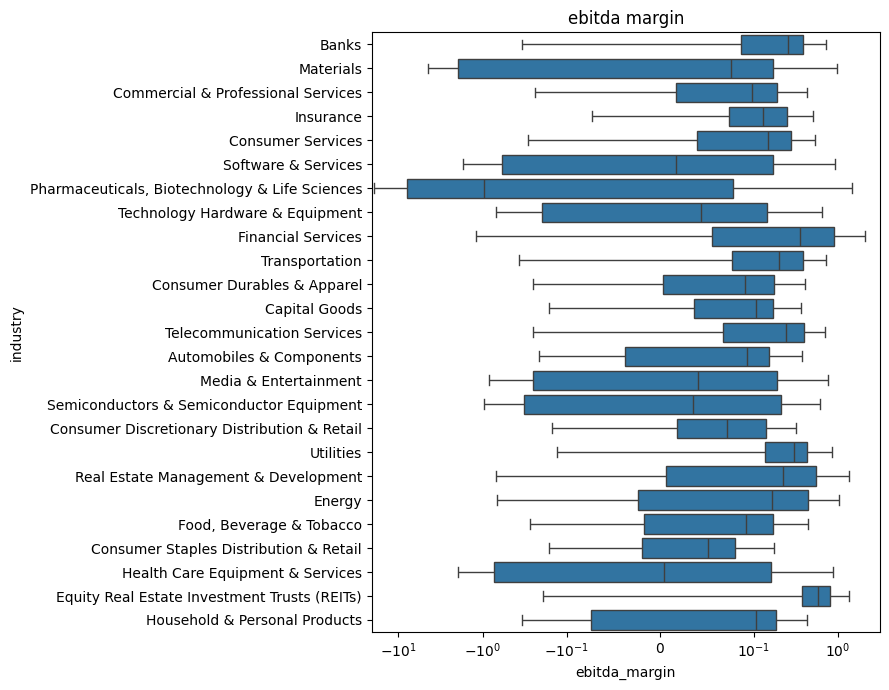

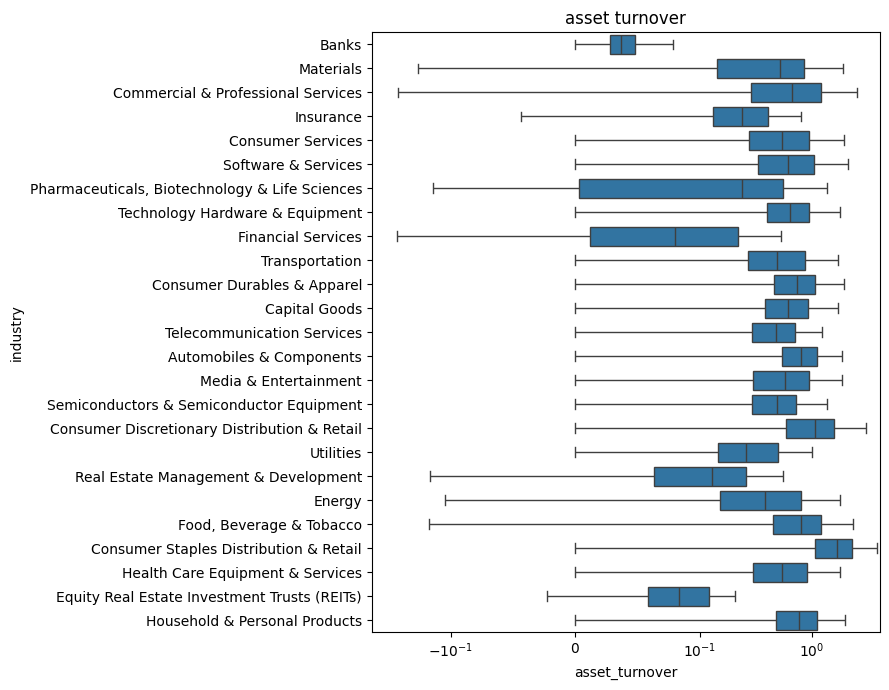

In [5]:
reference_data = df_fit.drop_duplicates('id')  # [05.01] Use each fitting company ID once in the financial reference data.
# [05.02] Display usable financial counts and industry medians.
display(reference_data.groupby('industry')[ratios].agg(['count', 'median']))
# [05.03] Store sorted observed values for every fitting industry and ratio.
profiles = {(industry, column): np.sort(group[column].dropna().to_numpy())
            for industry, group in reference_data.groupby('industry') for column in ratios}
for column in ratios:  # [05.04] Draw one financial-distribution plot per ratio.
    plt.figure(figsize=(9, 7))  # [05.05] Choose enough height for the industry labels.
    # [05.06] Show boxplot summaries while hiding only the outlier dots.
    sns.boxplot(data=reference_data, x=column, y='industry', showfliers=False)
    # [05.07] Keep losses and extreme positive values visible with symmetric logarithmic scaling.
    plt.xscale('symlog', linthresh=0.1)
    plt.title(column.replace('_', ' '))  # [05.08] Use a readable financial-ratio title.
    plt.tight_layout()  # [05.09] Adjust the plot layout for the long industry labels.
    plt.show()  # [05.10] Show this financial-distribution plot.


Financial distributions overlap substantially. Losses remain visible, and EBITDA margin is missing in **65.2%** of raw financial records before infinity handling. Across industry-ratio references, usable counts range from **66 to 6,193**. The evidence is incomplete and does not uniquely identify an industry.

## Official score and confidence features

Confidence estimates the probability that the selected label is correct.
For financial mid-rank `u`, compatibility is `2 × min(u, 1 − u)`. This is a
bounded statistical rank measure, rather than a calibrated probability or
formal p-value. Missing ratios are excluded. Compatibility 0.5 with
availability zero explicitly represents absent evidence.

In [6]:
def confidence_score(y_true, y_pred, confidence):  # [06.01] Define the current course confidence-score interface.
    # [06.02] Convert true and predicted labels to arrays for elementwise comparison.
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)  # [06.03] Convert the confidence vector to floating-point values.
    # [06.04] Check that each target has a prediction and a confidence.
    assert len(y_true) == len(y_pred) == len(confidence)
    # [06.05] Reject values outside the required finite probability interval.
    assert np.all((confidence >= 0) & (confidence <= 1))
    # [06.06] Compute F1 weighted by the true class supports, without confidence weights.
    f1 = f1_score(y_true, y_pred, average='weighted')
    correct = (y_true == y_pred).astype(float)  # [06.07] Represent prediction correctness as one and error as zero.
    brier = np.mean((confidence - correct) ** 2)  # [06.08] Measure mean squared correctness-probability error.
    return f1 * (1 - brier)  # [06.09] Apply exactly weighted F1 times one minus Brier.

# [06.10] Construct confidence evidence without reading any true input industry.
def confidence_features(rows, inputs, weight):
    p_lr, p_knn, distance = inputs  # [06.11] Unpack both class-probability matrices and nearest-neighbor distances.
    # [06.12] Mix the aligned class probabilities with the selected LR weight.
    votes = weight * p_lr + (1 - weight) * p_knn
    # [06.13] Choose the class and sort votes to recover the largest two values.
    prediction, top = votes.argmax(1), np.sort(votes, axis=1)
    # [06.14] Translate predicted class codes to the financial-profile industry names.
    names = le.inverse_transform(prediction)
    financial = rows.reindex(columns=ratios)  # [06.15] Represent absent financial columns as missing values.
    # [06.16] Start each row's compatibility total and evidence count at zero.
    total, available = np.zeros(len(rows)), np.zeros(len(rows))
    # [06.17] Visit the fitting-only industry-ratio reference samples.
    for (industry, column), reference in profiles.items():
        if len(reference) == 0:  # [06.18] Check whether a reference contains any observed fitting values.
            continue  # [06.19] Skip an empty reference rather than divide by zero.
        values = financial[column].to_numpy()  # [06.20] Read this ratio in exactly the input-row order.
        mask = (names == industry) & np.isfinite(values)  # [06.21] Use finite values for the predicted industry only.
        # [06.22] Count reference observations strictly below each value.
        left = np.searchsorted(reference, values[mask], side='left')
        # [06.23] Count reference observations below or equal to each value.
        right = np.searchsorted(reference, values[mask], side='right')
        u = (left + right) / (2 * len(reference))  # [06.24] Calculate empirical mid-ranks, including ties.
        total[mask] += 2 * np.minimum(u, 1 - u)  # [06.25] Add bounded central-rank compatibility for this observed ratio.
        available[mask] += 1  # [06.26] Count this usable financial contribution.
    # [06.27] Average available evidence and use 0.5 only when none is present.
    compatibility = np.divide(total, available, out=np.full(len(rows), 0.5), where=available > 0)
    q = np.clip(top[:, -1], 1e-6, 1 - 1e-6)  # [06.28] Clip the largest vote solely to keep its log-odds finite.
    # [06.29] Combine log-odds, margin, agreement, distance, financial rank, and availability.
    features = np.column_stack([np.log(q / (1 - q)), top[:, -1] - top[:, -2],
                               p_lr.argmax(1) == p_knn.argmax(1), np.log1p(distance),
                               compatibility, available / len(ratios)])
    return prediction, features  # [06.30] Return industry codes and the six confidence-feature columns.


## Fitting confidence

An earlier development comparison selected C=10, 128 components, 15 neighbors,
and a 25% LR / 75% k-NN vote using the official score. It split the calibration
pool into fitting and selection halves; final confidence fitting uses the
whole pool. Validation outcomes select no settings. A text-only confidence
model provides an ablation for financial evidence.

In [7]:
weight = 0.25  # [07.01] Use the development-selected 25 percent LR and 75 percent k-NN vote.
# [07.02] Build labels and confidence inputs on the entire held-out calibration pool.
prediction_cal, features_cal = confidence_features(df_cal, input_cal, weight)
# [07.03] Scale confidence features before regularized correctness logistic regression.
calibrator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# [07.04] Learn correctness, rather than industry labels, on calibration records only.
calibrator.fit(features_cal, prediction_cal == y_cal)
# [07.05] Create the same model for the text-only financial-evidence ablation.
text_calibrator = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
# [07.06] Fit that ablation using the same records and first four features.
text_calibrator.fit(features_cal[:, :4], prediction_cal == y_cal)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

## Validation, calibration, and human review

The comparison includes a plain LR baseline on the same records. Confidence
does not change the predicted label or remove difficult cases from scoring.
The final private-test threshold and score cannot be inferred from local data.

,Weighted F1,Brier,Official score,Difference from plain LR
Method,,,,
Plain LR,0.777788,0.137087,0.671163,0.000000
Plain k-NN,0.771401,0.141496,0.662251,-0.008912
Raw vote,0.780881,0.137380,0.673604,0.002441
Text calibration,0.780881,0.134588,0.675785,0.004621
Financial calibration,0.780881,0.133534,0.676607,0.005444


,Count,Confidence,Accuracy
Confidence,,,
"(0.2, 0.3]",11,0.275965,0.454545
"(0.3, 0.4]",89,0.362116,0.348315
"(0.4, 0.5]",222,0.453534,0.472973
"(0.5, 0.6]",306,0.547672,0.506536
"(0.6, 0.7]",325,0.651478,0.655385
"(0.7, 0.8]",401,0.752062,0.763092
"(0.8, 0.9]",619,0.852042,0.851373
"(0.9, 1.0]",1198,0.968253,0.960768


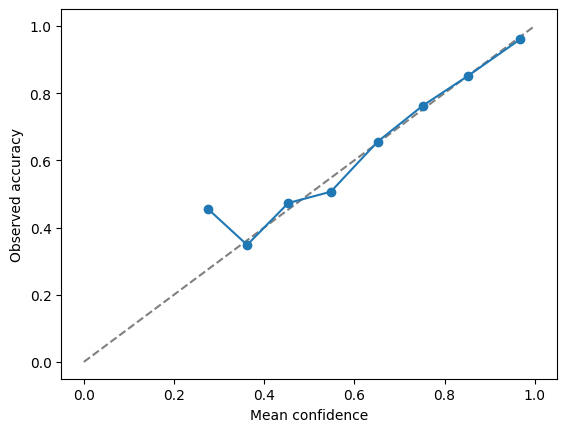

,Count,Accuracy
False,1817,0.92350
True,1354,0.60192


Review fraction: 0.4269946389151687 | errors captured: 539


In [8]:
# [08.01] Build the selected ensemble's validation labels and confidence features.
prediction_val, features_val = confidence_features(df_val, input_val, weight)
# [08.02] Read the fitted probability of the correct-prediction class.
confidence_val = calibrator.predict_proba(features_val)[:, 1]
# [08.03] Compare plain classifiers, raw voting, and both calibrated confidence methods.
methods = {'Plain LR': (input_val[0].argmax(1), input_val[0].max(1)),
           'Plain k-NN': (input_val[1].argmax(1), input_val[1].max(1)),
           'Raw vote': (prediction_val, (weight * input_val[0] + (1 - weight) * input_val[1]).max(1)),
           'Text calibration': (prediction_val, text_calibrator.predict_proba(features_val[:, :4])[:, 1]),
           'Financial calibration': (prediction_val, confidence_val)}
# [08.04] Compute weighted F1, correctness Brier, and the official score for each method.
results = [[name, f1_score(y_val, prediction, average='weighted'),
            np.mean((confidence - (prediction == y_val)) ** 2), confidence_score(y_val, prediction, confidence)]
           for name, (prediction, confidence) in methods.items()]
# [08.05] Create a compact table of the actual validation results.
scores = pd.DataFrame(results, columns=['Method', 'Weighted F1', 'Brier', 'Official score']).set_index('Method')
# [08.06] Calculate the paired-split score difference from plain LR.
scores['Difference from plain LR'] = scores['Official score'] - scores.loc['Plain LR', 'Official score']
display(scores)  # [08.07] Display the baseline and ensemble results together.
# [08.08] Pair each validation confidence with its observed correctness.
outcomes = pd.DataFrame({'Confidence': confidence_val, 'Correct': prediction_val == y_val})
# [08.09] Summarize occupied fixed-width confidence bins with counts and accuracy.
reliability = outcomes.groupby(pd.cut(outcomes.Confidence, np.linspace(0, 1, 11), include_lowest=True), observed=True).agg(
    Count=('Correct', 'size'), Confidence=('Confidence', 'mean'), Accuracy=('Correct', 'mean'))
display(reliability)  # [08.10] Display the reliability-bin evidence, including sample sizes.
plt.plot([0, 1], [0, 1], '--', color='gray')  # [08.11] Draw the ideal confidence-equals-accuracy reference.
plt.plot(reliability.Confidence, reliability.Accuracy, 'o-')  # [08.12] Plot the model's observed reliability points.
plt.xlabel('Mean confidence')  # [08.13] Label the average-confidence axis.
plt.ylabel('Observed accuracy')  # [08.14] Label the observed-correctness axis.
plt.show()  # [08.15] Show the reliability plot.
review = confidence_val < 0.8  # [08.16] Flag confidence below 0.8 under a fixed illustrative review policy.
# [08.17] Compare flagged and retained groups without removing records from scoring.
display(outcomes.groupby(review).agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
# [08.18] Report the review workload and how many errors it captures.
print('Review fraction:', review.mean(), '| errors captured:', np.sum(review & (prediction_val != y_val)))


The ensemble has weighted F1 **0.78088**. Financial calibration reduces Brier to **0.13353** and gives official score **0.67661**, versus **0.67116** for plain LR on the same companies. The local gain is **0.54 percentage points**; the separate guide reports an approximate grouped-bootstrap interval that includes zero. Financial inputs add only a small gain over text calibration. The final private bonus threshold remains unknown.

Review flags **1,354 of 3,171 records (42.7%)**, capturing **539 of 678 errors (79.5%)**. Flagged accuracy is **60.19%**, while retained accuracy is **92.35%**. All records remain in the official score.

## Predicting new companies

Return `(y_pred, y_confidence)` as two one-dimensional arrays in input-row
order, with industry names and confidence in [0, 1]. The embedding column is
required. Financial ratio columns are optional; join separate financial
records by ID as in the loading cell. No true industry label is read.

In [9]:
def predict_industry(companies):  # [09.01] Expose the required prediction-and-confidence tuple interface.
    # [09.02] Reuse the parser, fitted base models, vote, and financial evidence.
    prediction, features = confidence_features(companies, model_inputs(embeddings(companies)), weight)
    # [09.03] Return industry names and correctness probabilities in input-row order.
    return le.inverse_transform(prediction), calibrator.predict_proba(features)[:, 1]

# [09.04] Demonstrate inference after removing the true industry labels.
names, confidence = predict_industry(df_val.drop(columns='industry').head(3))
# [09.05] Display three predicted industry/confidence pairs.
display(pd.DataFrame({'Prediction': names, 'Confidence': confidence}))
# [09.06] Identify exact stored embedding strings also present among fitting records.
seen = df_val.business_description_embedding.isin(df_fit.business_description_embedding)
# [09.07] Compare accuracy on seen and unseen stored representations.
display(pd.DataFrame({'Embedding seen in fitting': seen.to_numpy(), 'Correct': prediction_val == y_val})
        .groupby('Embedding seen in fitting').agg(Count=('Correct', 'size'), Accuracy=('Correct', 'mean')))
# [09.08] Report elapsed notebook time after imports.
print('Elapsed notebook seconds:', round(perf_counter() - started, 1))


,Prediction,Confidence
0,Capital Goods,0.694004
1,Materials,0.997224
2,Consumer Services,0.887099


,Count,Accuracy
Embedding seen in fitting,,
False,2716,0.751473
True,455,0.993407


Elapsed notebook seconds: 77.4


**455 validation records (14.35%)** share an exact stored embedding string with fitting records. Accuracy is **99.34%** on those and **75.15%** on unseen stored representations. ID separation therefore does not establish entirely new-description performance.

This cloud run, including separate checks, took **80.5 seconds** with a conservative runner-plus-kernel peak-memory upper bound of **1.37 GiB**. The private score and timing on a particular mid-tier laptop remain unmeasured.

## Scope

Report the actual supplied record count, which may differ from the assignment's
broader 40,000+ company description. Repeated representations can make unseen
company IDs easier to classify. Previously inspected local validation data are
not a new independent test. Local timing documents this machine and does not
certify every mid-tier laptop. The final submission must train within 45 minutes
on the specified hardware and 16 GB RAM. The private result remains unknown.

AI assistance was used in development and review.